# Nepali Automatic Speech Recognition — Zero-Shot Baseline

**Model:** OpenAI Whisper Small (`openai/whisper-small`)  
**Dataset:** OpenSLR-54 Nepali, held-out test split  
**Task:** Nepali speech transcription (`language="nepali"`, `task="transcribe"`)  
**Environment:** Google Colab GPU

## Objective

Establish a reproducible zero-shot baseline before comparing full fine-tuning and parameter-efficient fine-tuning methods such as LoRA and QLoRA.

This notebook covers:
- Environment and dataset verification
- Pretrained Whisper loading and a small inference smoke test
- Batched inference with checkpoint/resume support
- WER, CER, and inference-performance evaluation
- Error analysis, decoding diagnostics, and audio visualizations


## Notebook workflow

Run the notebook from top to bottom in a GPU-enabled Colab runtime. If the runtime disconnects during inference, reconnect Drive, restore the runtime variables, and resume from the saved checkpoint.

In [2]:
import torch
import os

print("PyTorch Version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("Please enable GPU in Runtime settings.")

PyTorch Version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


## 1. Configure the project directory

Mount Google Drive before this step. `PROJECT_DIR` should point to the folder containing the train/validation/test manifests and audio directories.

In [4]:
PROJECT_DIR = "/content/drive/MyDrive/Nepali_Whisper_Project"

print(os.listdir(PROJECT_DIR))

['metadata.csv', 'audio_manifest.csv', 'duration_sample.csv', 'duration_statistics.csv', 'speaker_statistics.csv', 'speaker_assignment.csv', 'train_manifest.csv', 'validation_manifest.csv', 'test_manifest.csv', 'selected_manifest.csv', 'audio', 'audio_quality_report_backup.csv', 'audio_quality_report.csv', 'transcription_quality_report.csv', 'transcription_quality_report_backup.csv', 'download_progress.csv', 'drive_sync_test.txt']


## 2. Install required packages

Install the libraries used for model loading, audio processing, inference, and evaluation. If Colab reports dependency-conflict warnings, verify the imports in the next cell before continuing.

In [5]:
!pip install -q "transformers>=4.45,<5" accelerate jiwer soundfile librosa

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2.1 Verify the runtime and package versions

Record the installed versions and confirm that CUDA is available. Keeping these details helps make later timing and memory comparisons interpretable.

In [6]:
import torch
import transformers
import huggingface_hub
import jiwer
import soundfile

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Whisper dependencies imported successfully!")

PyTorch: 2.14.1+cu130
Transformers: 4.57.6
Hugging Face Hub: 0.36.2
CUDA available: True
Whisper dependencies imported successfully!


## 3. Inspect the evaluation dataset

Load the held-out test manifest and confirm its structure before inference. The test split is kept separate from training and validation and will be reused unchanged when evaluating fine-tuned models.

**Expected manifest fields:** at minimum, the test manifest should contain a stable `file_id` and the reference `transcription`. Additional metadata may include speaker ID, split, and archive information.

In [7]:
import pandas as pd
test_manifest = pd.read_csv(f"{PROJECT_DIR}/test_manifest.csv")

print("Test Samples:", len(test_manifest))
print("\n Columns:")
print(test_manifest.columns.to_list())

display(test_manifest.head())

Test Samples: 7495

 Columns:
['file_id', 'archive_prefix', 'archive_path', 'file_size', 'compressed_size', 'speaker_id', 'transcription', 'split']


,file_id,archive_prefix,archive_path,file_size,compressed_size,speaker_id,transcription,split
0,00ee752d8d,0,asr_nepali/data/00/00ee752d8d.flac,51006,51006,e72b0,गेटा आँखा अस्पताल,test
1,006bd9a275,0,asr_nepali/data/00/006bd9a275.flac,59387,59387,6d3c6,प्रस्तोता र भारतीय,test
2,007e72e734,0,asr_nepali/data/00/007e72e734.flac,44974,44974,d0cd7,छुट्टाउँदै कर्णाली चिसापानी,test
3,00dbbdaa2c,0,asr_nepali/data/00/00dbbdaa2c.flac,53299,53299,d8cef,भएको हुन्छ,test
4,00b316fa0b,0,asr_nepali/data/00/00b316fa0b.flac,74223,74223,5f3e5,अन्यले राष्ट्रिय,test


## 4. Verify audio files and metadata

Check that a manifest entry points to a readable audio file and inspect its sample rate, shape, and duration. Whisper expects audio sampled at 16 kHz; this dataset was prepared at that rate.

The check below validates one sample path and reads its audio metadata. Later inference cells verify the sample rate for every recording.

In [8]:
import os
import soundfile as sf

AUDIO_DIR = f"{PROJECT_DIR}/audio/test"

# Build the path for the first test sample
sample_id = test_manifest.iloc[0]["file_id"]
sample_path = f"{AUDIO_DIR}/{sample_id}.flac"

print("Audio path:", sample_path)
print("File exists:", os.path.exists(sample_path))

if os.path.exists(sample_path):
    audio, sr = sf.read(sample_path)
    print("Sample rate:", sr)
    print("Audio shape:", audio.shape)
    print("Duration:", len(audio) / sr, "seconds")

Audio path: /content/drive/MyDrive/Nepali_Whisper_Project/audio/test/00ee752d8d.flac
File exists: True
Sample rate: 16000
Audio shape: (54400,)
Duration: 3.4 seconds


## 5. Load the pretrained Whisper Small model

Load the processor (feature extractor + tokenizer) and pretrained encoder-decoder model. This notebook evaluates the pretrained checkpoint without updating its weights.

The processor converts waveform audio into Whisper log-mel input features and converts generated token IDs back into text. The model is loaded in FP16 on the Colab GPU to reduce inference memory use.

In [9]:
import torch
from transformers import WhisperProcessor, WhisperForConditionalGeneration

MODEL_NAME = "openai/whisper-small"

processor = WhisperProcessor.from_pretrained(MODEL_NAME) # processor = tokenizer + feature extractor

model = WhisperForConditionalGeneration.from_pretrained(MODEL_NAME,
                                                        torch_dtype=torch.float16
                                                        ).to("cuda")

model.eval()
print("Whisper Small loaded successfully!")
print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (4 outputs left out)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

Whisper Small loaded successfully!
Model device: cuda:0
Model dtype: torch.float16


## 6. Verify Nepali transcription configuration

Confirm that the tokenizer contains the Nepali language token. During generation, explicitly set `language="nepali"` and `task="transcribe"` so Whisper is prompted to produce Nepali text rather than translate it.

This is a tokenizer-level check. The actual generation prompt is also explicitly set to Nepali transcription in the inference cells.

In [10]:
print("Nepali Language token available:")

print([
    token for token in processor.tokenizer.additional_special_tokens
    if "ne" in token.lower()
])

Nepali Language token available:
['<|ne|>']


## 7. Smoke test: verify end-to-end inference

Run a small number of examples before processing the full test set. This checks audio loading, feature extraction, GPU inference, and decoding.

The smoke test reports predictions for five recordings. It is intended to validate the pipeline, not to estimate model accuracy; the full test-set evaluation below is the benchmark.

In [17]:
import soundfile as sf
import pandas as pd
import torch

#selecting 5 samples
smoke_test = test_manifest.head(5).copy()

results = []

for _,row  in smoke_test.iterrows():

  audio_path = f"{PROJECT_DIR}/audio/test/{row['file_id']}.flac"

# Load audio
  audio, sr = sf.read(audio_path)

  #converting audio into Whisper input features
  inputs = processor(audio, sampling_rate=sr, return_tensors='pt', return_attention_mask=True)

  input_features = inputs.input_features.to(device="cuda", dtype=torch.float16)

  attention_mask = inputs.attention_mask.to("cuda")

  # Check whether features differ between recordings
  feature_mean = input_features.float().mean().item()
  feature_std = input_features.float().std().item()


  #Generating Nepali Transcription
  with torch.inference_mode():
    predicted_ids = model.generate(
        input_features,
        language="nepali",
        task="transcribe"
    )

    #converting token IDs into readable text
    predicted_text = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    results.append({
        "file_id": row["file_id"],
        "reference": row["transcription"],
        "prediction": predicted_text,
        "feature_mean": round(feature_mean, 5),
        "feature_std": round(feature_std, 5)
    })


results_df = pd.DataFrame(results)
# # Display results
# smoke_test["prediction"] = predictions

# display(
#     smoke_test[["file_id", "transcription", "prediction"]]
# )


Review the reference/prediction pairs. If audio loading or decoding fails here, resolve that issue before launching full inference.

In [18]:
results_df

,file_id,reference,prediction,feature_mean,feature_std
0,00ee752d8d,गेटा आँखा अस्पताल,गेटा आखा अस्पताल,-0.98166,0.23688
1,006bd9a275,प्रस्तोता र भारतीय,प्रस्टो तार बारतिय,-0.67079,0.21665
2,007e72e734,छुट्टाउँदै कर्णाली चिसापानी,जद्ताउने करनाली ची सापानी,-0.93866,0.23574
3,00dbbdaa2c,भएको हुन्छ,बाए को ओन्चा,-0.83034,0.22742
4,00b316fa0b,अन्यले राष्ट्रिय,अन्नेले रास्टिया,-0.89749,0.31623


## 8. Prepare a small batched inference test

Set up the output directory and batch configuration, then verify that a batch can be converted into Whisper features and passed through `generate()`.

The following cell defines a small batch and creates the results directory. The small-batch experiment is a pipeline check, not the final throughput benchmark.

In [19]:
import os
import time
import numpy as np
import pandas as pd
import torch
import soundfile as sf
from jiwer import wer, cer

BATCH_SIZE = 4

RESULTS_DIR = f"{PROJECT_DIR}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Test samples:", len(test_manifest))
print("Batch size:", BATCH_SIZE)
print("Results directory:", RESULTS_DIR)

Test samples: 7495
Batch size: 4
Results directory: /content/drive/MyDrive/Nepali_Whisper_Project/results


Load a few recordings, extract Whisper features, run generation, and print the decoded hypotheses alongside their references.

In [20]:
batch_samples = test_manifest.head(4)

audio_list = []
references = []
file_ids = []

#Loading audio files
for _, row  in batch_samples.iterrows():

  audio_path = f"{PROJECT_DIR}/audio/test/{row['file_id']}.flac"

  audio, sr = sf.read(audio_path)

  audio_list.append(audio)
  references.append(row["transcription"])
  file_ids.append(row["file_id"])


# extracting whisper features for the batch

inputs =  processor(
    audio_list,
    sampling_rate=16000,
    return_tensors="pt",
    padding="max_length",
    truncation=True,
    return_attention_mask=True
)

input_features = inputs.input_features.to(
    device="cuda",
    dtype=torch.float16
)

attention_mask = inputs.attention_mask.to("cuda")

# Generate predictions
with torch.inference_mode():
  predicted_ids = model.generate(
      input_features,
      attention_mask=attention_mask,
      language="nepali",
      task="transcribe"
  )

predictions = processor.batch_decode(
    predicted_ids,
    skip_special_tokens=True
)

# Displaay results

for file_id, reference, prediction in zip(
    file_ids, references, predictions
):
    print("File ID:", file_id)
    print("Reference:", reference)
    print("Prediction:", prediction)
    print("-" * 60)

File ID: 00ee752d8d
Reference: गेटा आँखा अस्पताल
Prediction:  गेटा आखा अस्पताल
------------------------------------------------------------
File ID: 006bd9a275
Reference: प्रस्तोता र भारतीय
Prediction:  प्रस्टो तार बारतिय
------------------------------------------------------------
File ID: 007e72e734
Reference: छुट्टाउँदै कर्णाली चिसापानी
Prediction:  जद्ताउने करनाली ची सापानी
------------------------------------------------------------
File ID: 00dbbdaa2c
Reference: भएको हुन्छ
Prediction:  बाए को ओन्चा
------------------------------------------------------------


## 9. Full zero-shot inference

Run Whisper Small on the complete held-out test split without fine-tuning. Predictions are checkpointed so an interrupted Colab session can resume rather than starting from zero.

Inspect GPU availability and memory before running the full test set. The exact GPU model and available memory should be recorded with the benchmark results.

In [22]:
!nvidia-smi

Mon Nov  9 02:46:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P0             26W /   70W |     985MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 9.1 Stage test audio on local Colab storage

Copy the test audio from Google Drive to the Colab runtime disk. Reading local files can reduce repeated Drive I/O during batch inference. The copy is temporary and must be recreated after a runtime reset.

In [23]:
import os
import shutil

LOCAL_AUDIO_DIR = "/content/test_audio"

if not os.path.exists(LOCAL_AUDIO_DIR):
    shutil.copytree(
        f"{PROJECT_DIR}/audio/test",
        LOCAL_AUDIO_DIR
    )

print("Audio copied successfully!")

!du -sh /content/test_audio

Audio copied successfully!
476M	/content/test_audio


Set the batch size for the small-subset inference check. The final full-test batch size is configured separately in the checkpoint setup below.

In [24]:
BATCH_SIZE = 8

### 9.2 Validate batched inference on a small subset

Before running all 7,495 test recordings, test the pipeline on a small subset and confirm that decoded predictions are returned.

This test verifies that batched generation works with the chosen batch size. Check that predictions are produced and that no out-of-memory error occurs.

In [25]:
batch_samples = test_manifest.head(20)

for start in range(0, len(batch_samples), BATCH_SIZE):

    batch = batch_samples.iloc[start:start + BATCH_SIZE]

    audio_list = []

    for _, row in batch.iterrows():

        audio_path = f"{LOCAL_AUDIO_DIR}/{row['file_id']}.flac"

        audio, sr = sf.read(audio_path)
        audio_list.append(audio)

    inputs = processor(
        audio_list,
        sampling_rate=16000,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    input_features = inputs.input_features.to(
        device="cuda",
        dtype=torch.float16
    )

    attention_mask = inputs.attention_mask.to("cuda")

    with torch.inference_mode():
        predicted_ids = model.generate(
            input_features,
            attention_mask=attention_mask,
            language="nepali",
            task="transcribe"
        )

    predictions = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )

    for prediction in predictions:
        print(prediction)

 गेटा आखा अस्पताल
 प्रस्टो तार बारतिय
 जद्ताउने करनाली ची सापानी
 बाए को ओन्चा
 अन्नेले रास्टिया
 निता कारुप माहाप लाई
 उन्ले स्ण उन्नेसे और्षर्टी देखी
 भिध्तारिद गर्ये पची
 उद्टरी च्ट्राका लागी
 येस्को पातलाए
 अस्पत्ताल काश्मन नुको
 बनुनु होस एक जोटी
 शिज़ा लान को लूजरन बने
 प्रदादादा बद्टाचारी ले
 जुरेरी निपाल मा पाईने
 जो विषी मेगा वार्चा
 च्याता अप दि हरु को चा
 सुद्र पस्टिम्मा भिवाहा
 प्रस्तूत भईको चार
 पनी ताकम


### 9.3 Configure checkpointing and resume behavior

Define the batch size, checkpoint interval, output paths, and execution device. Existing checkpoint rows are loaded and their file IDs are excluded from the remaining inference queue.

The checkpoint CSV is a recovery file; the final predictions CSV is the artifact used for evaluation. The checkpoint filename contains a batch-size label, so ensure that the actual `BATCH_SIZE` used in a run is recorded accurately if it is changed.

In [26]:
import os
import time
import unicodedata
import pandas as pd
import soundfile as sf
import torch

from tqdm.auto import tqdm
from jiwer import wer, cer

# Configuration
BATCH_SIZE = 8
CHECKPOINT_EVERY = 100

LOCAL_AUDIO_DIR = "/content/test_audio"

RESULTS_DIR = f"{PROJECT_DIR}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

CHECKPOINT_PATH = f"{RESULTS_DIR}/zero_shot_checkpoint_bs8.csv"
FINAL_PATH = f"{RESULTS_DIR}/zero_shot_whisper_small_predictions.csv"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("Test samples:", len(test_manifest))
print("Batch size:", BATCH_SIZE)

# Load existing checkpoint if available
if os.path.exists(CHECKPOINT_PATH):

    results_df = pd.read_csv(CHECKPOINT_PATH)

    completed_ids = set(results_df["file_id"].astype(str))
    results = results_df.to_dict("records")

    print("Resuming from checkpoint.")
    print("Completed:", len(completed_ids))

else:

    results = []
    completed_ids = set()

    print("Starting from scratch.")

# Select remaining samples
remaining = test_manifest[
    ~test_manifest["file_id"].astype(str).isin(completed_ids)
].reset_index(drop=True)

print("Remaining samples:", len(remaining))

Device: cuda
Test samples: 7495
Batch size: 8
Starting from scratch.
Remaining samples: 7495


### 9.4 Load the inference model with SDPA

Reload Whisper Small using PyTorch scaled dot-product attention (SDPA). This is an inference optimization; it does not change the model weights or constitute fine-tuning.

Reload the model with SDPA enabled. The subsequent full-test run uses this model instance. Keep the default decoding behavior for the primary zero-shot baseline; decoding constraints explored later are diagnostic experiments only.

In [30]:
import gc
import torch

# Release existing model
del model
gc.collect()
torch.cuda.empty_cache()

# Load Whisper Small with optimized attention
model = WhisperForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    attn_implementation="sdpa"
).to("cuda")

model.eval()

print("Whisper loaded with SDPA attention.")

Whisper loaded with SDPA attention.


### 9.5 Exploratory inference-speed experiment

This cell measures a short benchmark subset after a warm-up. Warm-up is excluded from the timed section. Treat this as a local optimization experiment, not as the full-test runtime.

In [31]:
# Warm-up (not included in timing)
warmup_inputs = processor(
    benchmark_data.head(8).apply(
        lambda row: sf.read(
            f"{LOCAL_AUDIO_DIR}/{row['file_id']}.flac"
        )[0],
        axis=1
    ).tolist(),
    sampling_rate=16000,
    return_tensors="pt",
    padding="max_length",
    truncation=True,
    return_attention_mask=True
)

with torch.inference_mode():
    model.generate(
        warmup_inputs.input_features.to("cuda", dtype=torch.float16),
        attention_mask=warmup_inputs.attention_mask.to("cuda"),
        language="nepali",
        task="transcribe"
    )

torch.cuda.synchronize()

# Timed benchmark
start_time = time.perf_counter()

for start in range(0, len(benchmark_data), 8):

    batch = benchmark_data.iloc[start:start + 8]

    audio_list = [
        sf.read(f"{LOCAL_AUDIO_DIR}/{fid}.flac")[0]
        for fid in batch["file_id"].astype(str)
    ]

    inputs = processor(
        audio_list,
        sampling_rate=16000,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    with torch.inference_mode():

        model.generate(
            inputs.input_features.to("cuda", dtype=torch.float16),
            attention_mask=inputs.attention_mask.to("cuda"),
            language="nepali",
            task="transcribe"
        )

torch.cuda.synchronize()

sdpa_time = time.perf_counter() - start_time

print(f"SDPA inference time: {sdpa_time:.2f} seconds")
print(f"Throughput: {32 / sdpa_time:.2f} samples/second")

SDPA inference time: 21.92 seconds
Throughput: 1.46 samples/second


### 9.6 Compare a larger inference batch

Test a batch size of 16 and record elapsed time, throughput, and peak allocated GPU memory. Results can vary with runtime state, warm-up, and batch composition; repeat measurements if making a strict performance claim.

In [35]:
import time
import torch
import soundfile as sf

BATCH_SIZE_TEST = 16

# Warm-up (not included in timing)
warmup_audio = [
    sf.read(f"{LOCAL_AUDIO_DIR}/{fid}.flac")[0]
    for fid in benchmark_data.head(BATCH_SIZE_TEST)["file_id"].astype(str)
]

warmup_inputs = processor(
    warmup_audio,
    sampling_rate=16000,
    return_tensors="pt",
    padding="max_length",
    truncation=True,
    return_attention_mask=True
)

try:
    with torch.inference_mode():
        model.generate(
            warmup_inputs.input_features.to("cuda", dtype=torch.float16),
            attention_mask=warmup_inputs.attention_mask.to("cuda"),
            language="nepali",
            task="transcribe"
        )

    torch.cuda.synchronize()

    # Timed benchmark
    torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    for start in range(0, len(benchmark_data), BATCH_SIZE_TEST):
        batch = benchmark_data.iloc[start:start + BATCH_SIZE_TEST]

        audio_list = [
            sf.read(f"{LOCAL_AUDIO_DIR}/{fid}.flac")[0]
            for fid in batch["file_id"].astype(str)
        ]

        inputs = processor(
            audio_list,
            sampling_rate=16000,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            return_attention_mask=True
        )

        with torch.inference_mode():
            model.generate(
                inputs.input_features.to("cuda", dtype=torch.float16),
                attention_mask=inputs.attention_mask.to("cuda"),
                language="nepali",
                task="transcribe"
            )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time

    print(f"Inference time: {elapsed:.2f} seconds")
    print(f"Throughput: {len(benchmark_data) / elapsed:.2f} samples/second")
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

except torch.cuda.OutOfMemoryError:
    print("Batch size 16 exceeded GPU memory.")
    torch.cuda.empty_cache()

Inference time: 16.25 seconds
Throughput: 1.97 samples/second
Peak GPU memory: 3.50 GB


### 9.7 Generate predictions for the remaining test recordings

Run inference in batches, append each result, and periodically save a checkpoint. The final CSV contains the file ID, reference, prediction, and audio duration for each processed recording.

**Important:** preserve the original zero-shot outputs. Do not replace them with outputs from repetition-penalty or length-limited decoding experiments when reporting the primary baseline.

In [36]:
 # Start timing
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_time = time.perf_counter()

# Process test samples in batches
for start in tqdm(
    range(0, len(remaining), BATCH_SIZE),
    desc="Whisper inference"
):

    batch = remaining.iloc[start:start + BATCH_SIZE]

    audio_list = []
    references = []
    file_ids = []
    durations = []

    # Load audio
    for _, row in batch.iterrows():

        file_id = str(row["file_id"])
        audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"

        audio, sr = sf.read(audio_path)

        if sr != 16000:
            raise ValueError(f"Unexpected sample rate: {sr}")

        audio_list.append(audio)
        references.append(row["transcription"])
        file_ids.append(file_id)
        durations.append(len(audio) / sr)

    # Extract Whisper features
    inputs = processor(
        audio_list,
        sampling_rate=16000,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    input_features = inputs.input_features.to(
        device=DEVICE,
        dtype=torch.float16 if DEVICE == "cuda" else torch.float32
    )

    attention_mask = inputs.attention_mask.to(DEVICE)

    # Generate predictions
    with torch.inference_mode():

        predicted_ids = model.generate(
            input_features,
            attention_mask=attention_mask,
            language="nepali",
            task="transcribe"
        )

    # Decode predictions
    predictions = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )

    # Store results
    for file_id, reference, prediction, duration in zip(
        file_ids, references, predictions, durations
    ):

        results.append({
            "file_id": file_id,
            "reference": reference,
            "prediction": prediction,
            "duration_seconds": duration
        })

    # Save checkpoint every 100 batches
    batch_number = start // BATCH_SIZE + 1

    if batch_number % CHECKPOINT_EVERY == 0:

        pd.DataFrame(results).to_csv(
            CHECKPOINT_PATH,
            index=False,
            encoding="utf-8-sig"
        )

# Finish timing
if DEVICE == "cuda":
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start_time

# Save final predictions
results_df = pd.DataFrame(results)

results_df.to_csv(
    FINAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Update checkpoint
results_df.to_csv(
    CHECKPOINT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nPrediction generation completed!")
print("Total predictions:", len(results_df))
print(f"Inference time: {inference_time / 60:.2f} minutes")
print("Saved to:", FINAL_PATH)

Whisper inference:   0%|          | 0/419 [00:00<?, ?it/s]


Prediction generation completed!
Total predictions: 7647
Inference time: 90.23 minutes
Saved to: /content/drive/MyDrive/Nepali_Whisper_Project/results/zero_shot_whisper_small_predictions.csv


## 10. Validate prediction coverage and uniqueness

Check that the prediction file covers every test ID, contains no unexpected IDs, and identify any duplicated rows created during checkpoint/resume operations.

In [37]:
predictions_df = pd.read_csv(FINAL_PATH)

print("Prediction rows:", len(predictions_df))
print("Unique file IDs:", predictions_df["file_id"].nunique())
print("Test manifest rows:", len(test_manifest))
print("Duplicate predictions:", predictions_df["file_id"].duplicated().sum())

print("\nMissing test IDs:",
      len(set(test_manifest["file_id"].astype(str)) -
          set(predictions_df["file_id"].astype(str))))

print("\nExtra prediction IDs:",
      len(set(predictions_df["file_id"].astype(str)) -
          set(test_manifest["file_id"].astype(str))))

Prediction rows: 7647
Unique file IDs: 7495
Test manifest rows: 7495
Duplicate predictions: 152

Missing test IDs: 0

Extra prediction IDs: 0


### 10.1 Deduplicate prediction records

If a file ID appears more than once, retain the latest saved row and rewrite the cleaned prediction file. Confirm that the final number of unique IDs matches the test manifest.

In [38]:
predictions_df = pd.read_csv(FINAL_PATH)

predictions_df = (
    predictions_df
    .drop_duplicates(subset="file_id", keep="last")
    .reset_index(drop=True)
)

print("Clean prediction count:", len(predictions_df))
print("Unique IDs:", predictions_df["file_id"].nunique())

predictions_df.to_csv(
    FINAL_PATH,
    index=False
)

Clean prediction count: 7495
Unique IDs: 7495


## 11. Evaluate zero-shot transcription quality and speed

Normalize Unicode to NFC, remove punctuation, and collapse whitespace before computing corpus-level WER and CER. The same normalization function should be reused for all model variants to keep the comparison fair.

Performance metrics include total audio duration, elapsed inference time, average time per sample, throughput, and real-time factor (RTF).

> **Metric distinction:** corpus WER/CER aggregate edit counts across the whole test set. Sample-level WER distributions are analyzed separately below.

In [39]:
import re
import unicodedata
import numpy as np
import pandas as pd
from jiwer import wer, cer

# Load cleaned predictions
predictions_df = pd.read_csv(FINAL_PATH)

# Remove duplicate predictions, just in case
predictions_df = (
    predictions_df
    .drop_duplicates(subset="file_id", keep="last")
    .reset_index(drop=True)
)

# Normalize Nepali text
def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))

    # Remove punctuation
    text = "".join(
        char for char in text
        if not unicodedata.category(char).startswith("P")
    )

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Prepare references and predictions
references = predictions_df["reference"].apply(normalize_text).tolist()
predictions = predictions_df["prediction"].apply(normalize_text).tolist()

# Calculate metrics
wer_score = wer(references, predictions)
cer_score = cer(references, predictions)

# Timing information
total_audio_seconds = predictions_df["duration_seconds"].sum()

inference_time_seconds = 90.23 * 60

rtf = inference_time_seconds / total_audio_seconds
throughput = len(predictions_df) / inference_time_seconds
avg_inference_time = inference_time_seconds / len(predictions_df)

# Display results
print("=" * 45)
print("ZERO-SHOT WHISPER SMALL EVALUATION")
print("=" * 45)

print(f"Test samples:              {len(predictions_df)}")
print(f"Unique file IDs:           {predictions_df['file_id'].nunique()}")

print("\n--- Accuracy Metrics ---")
print(f"WER:                       {wer_score:.4f} ({wer_score * 100:.2f}%)")
print(f"CER:                       {cer_score:.4f} ({cer_score * 100:.2f}%)")

print("\n--- Performance Metrics ---")
print(f"Total audio duration:      {total_audio_seconds / 3600:.2f} hours")
print(f"Inference time:            {inference_time_seconds / 60:.2f} minutes")
print(f"Average time per sample:   {avg_inference_time:.2f} seconds")
print(f"Throughput:                {throughput:.2f} samples/second")
print(f"RTF:                       {rtf:.4f}")

print("=" * 45)

ZERO-SHOT WHISPER SMALL EVALUATION
Test samples:              7495
Unique file IDs:           7495

--- Accuracy Metrics ---
WER:                       3.2321 (323.21%)
CER:                       1.8695 (186.95%)

--- Performance Metrics ---
Total audio duration:      7.86 hours
Inference time:            90.23 minutes
Average time per sample:   0.72 seconds
Throughput:                1.38 samples/second
RTF:                       0.1912


## 12. Sample-level error diagnostics

Calculate WER for each utterance and inspect prediction/reference length differences. These diagnostics help identify outliers that can be hidden by a single corpus-level metric.

In [40]:
from jiwer import wer
import pandas as pd

diagnostic_df = predictions_df.copy()

diagnostic_df["ref_clean"] = diagnostic_df["reference"].apply(normalize_text)
diagnostic_df["pred_clean"] = diagnostic_df["prediction"].apply(normalize_text)

diagnostic_df["ref_words"] = diagnostic_df["ref_clean"].str.split().str.len()
diagnostic_df["pred_words"] = diagnostic_df["pred_clean"].str.split().str.len()

diagnostic_df["sample_wer"] = diagnostic_df.apply(
    lambda row: wer([row["ref_clean"]], [row["pred_clean"]])
    if row["ref_words"] > 0 else 0,
    axis=1
)

print("Empty references:", (diagnostic_df["ref_words"] == 0).sum())
print("Empty predictions:", (diagnostic_df["pred_words"] == 0).sum())

print("\nAverage reference words:",
      diagnostic_df["ref_words"].mean())

print("Average predicted words:",
      diagnostic_df["pred_words"].mean())

print("\nAverage reference/prediction length ratio:",
      diagnostic_df["pred_words"].sum() /
      max(diagnostic_df["ref_words"].sum(), 1))

print("\n10 examples with highest sample WER:")

display(
    diagnostic_df.nlargest(10, "sample_wer")[
        ["file_id", "ref_clean", "pred_clean",
         "ref_words", "pred_words", "sample_wer"]
    ]
)

Empty references: 0
Empty predictions: 0

Average reference words: 2.9786524349566377
Average predicted words: 9.860973982655103

Average reference/prediction length ratio: 3.310548712206047

10 examples with highest sample WER:


,file_id,ref_clean,pred_clean,ref_words,pred_words,sample_wer
855,1d072a6163,सिद्धान्त बन्यो,तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ...,2,148,74.0
1336,2de965d9de,२०१८ असारमा,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
1618,36c23f4933,सारिएका छन्,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
2044,4422450561,डोनाल्ड थम्पसनलाई,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
2288,4df473fb0f,धोका पाइनेछ,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3155,6bc2ab3abc,२०२४ मार्गमा,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3426,745d70ae1f,स्वरूपले विवेचना,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3532,780fff944e,आइसिसी एसोसिएट,अईश्वाद अप आप आप आप आप आप आप आप आप आप आप आप आप...,2,148,74.0
3635,7cd336e97d,सजिलोको लागी,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3745,80dbb67133,शनिबारको पनि,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0


### 12.1 Identify unusually long generations

Compare predicted word counts with reference word counts. Extremely long outputs on short recordings can indicate decoder repetition or hallucination; length alone is a warning signal, not proof of the cause.

In [41]:
# Identify unusually long predictions

diagnostic_df["length_ratio"] = (
    diagnostic_df["pred_words"] /
    diagnostic_df["ref_words"].clip(lower=1)
)

print("Predictions longer than 20 words:",
      (diagnostic_df["pred_words"] > 20).sum())

print("Predictions more than 3x reference length:",
      (diagnostic_df["length_ratio"] > 3).sum())

print("\nPrediction word-count distribution:")
display(diagnostic_df["pred_words"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nLongest predictions:")
display(
    diagnostic_df.nlargest(15, "pred_words")[
        ["file_id", "reference", "prediction",
         "duration_seconds", "ref_words", "pred_words"]
    ]
)

Predictions longer than 20 words: 472
Predictions more than 3x reference length: 498

Prediction word-count distribution:


,pred_words
count,7495.000000
mean,9.860974
std,25.339512
min,1.000000
50%,4.000000
75%,5.000000
90%,6.000000
95%,63.300000
99%,148.000000
max,155.000000



Longest predictions:


,file_id,reference,prediction,duration_seconds,ref_words,pred_words
1707,392df6bcbb,सञ्चालन एबिसिद्वारा गरिएको,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,4.8,3,155
245,08bda1a56b,साँच्चै नै एक्लिए,अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो ...,2.6,3,154
5076,aff42224a0,सञ्चारमाध्यमले सबैभन्दा धेरै,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,4.5,3,154
4984,ac6a187d65,सोभियत सङ्घको सैन्य,तो आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,3.7,3,153
398,0d1b0060a1,सबै प्रकारकका हिंसाबाट,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,5.9,3,152
3794,82de3092bf,हुन्छ त्यसै कारणले,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,3.4,3,152
801,1bedd03788,एलिएन्ज एरिना म्युनिखमा,आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,8.2,3,149
4225,91e7bc7c2f,एफ डब्ल्यु डि क्लार्कसँग,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,6.9,4,149
4327,94c6863c89,फेसबुक र ट्विटर,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,3.2,3,149
143,04c3e481aa,केही वर्ष त मैले,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो ...,3.8,4,148


### 12.2 Compare individual inference with saved batch predictions

Listen to selected problematic and relatively successful recordings, then run each recording individually. This checks whether the observed output pattern is caused by batching or is also present in single-example generation.

In [42]:
from IPython.display import Audio, display

# Two problematic samples and one relatively normal sample
sample_ids = [
    "1d072a6163",  # Repeated "आप"
    "08bda1a56b",  # Repeated "अप यह तो"
    "00ee752d8d"   # Previously inspected normal sample
]

for file_id in sample_ids:

    row = predictions_df[
        predictions_df["file_id"].astype(str) == file_id
    ].iloc[0]

    audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"
    audio, sr = sf.read(audio_path)

    inputs = processor(
        audio,
        sampling_rate=sr,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    input_features = inputs.input_features.to(
        DEVICE, dtype=torch.float16
    )
    attention_mask = inputs.attention_mask.to(DEVICE)

    with torch.inference_mode():
        generated_ids = model.generate(
            input_features,
            attention_mask=attention_mask,
            language="nepali",
            task="transcribe"
        )

    single_prediction = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    print("\nFile ID:", file_id)
    print("Reference:", row["reference"])
    print("Original batch prediction:", row["prediction"])
    print("Individual prediction:", single_prediction)
    print("Audio duration:", round(len(audio) / sr, 2), "seconds")

    display(Audio(audio, rate=sr))


File ID: 1d072a6163
Reference: सिद्धान्त बन्यो
Original batch prediction:  तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ� आप आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� प आ� आ� प आ� प आ� प आ� प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प
Individual prediction:  तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ� आ� आप आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� प आ� आ� प आ� प आ� प आ� प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प
Audio duration: 4.4 seconds



File ID: 08bda1a56b
Reference: साँच्चै नै एक्लिए
Original batch prediction:  अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प प प प प प प प प प प प प
Individual prediction:  अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प प प प प प प प प प प प प
Audio duration: 2.6 seconds



File ID: 00ee752d8d
Reference: गेटा आँखा अस्पताल
Original batch prediction:  गेटा आखा अस्पताल
Individual prediction:  गेटा आखा अस्पताल
Audio duration: 3.4 seconds


### 12.3 Explore decoding constraints (diagnostic only)

Compare default generation with a length cap and repetition constraints on a few examples. These settings are diagnostic experiments: they may shorten loops but can also change recognition accuracy. Keep default decoding as the primary baseline unless a separate decoding configuration is deliberately benchmarked across the full test set.

In [43]:
test_ids = ["1d072a6163", "08bda1a56b", "00ee752d8d"]

for file_id in test_ids:

    row = predictions_df[
        predictions_df["file_id"].astype(str) == file_id
    ].iloc[0]

    audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"
    audio, sr = sf.read(audio_path)

    inputs = processor(
        audio,
        sampling_rate=sr,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    features = inputs.input_features.to(
        DEVICE, dtype=torch.float16
    )
    mask = inputs.attention_mask.to(DEVICE)

    configs = {
        "Default": {},
        "Length limited": {
            "max_new_tokens": 64
        },
        "Repetition constrained": {
            "max_new_tokens": 64,
            "repetition_penalty": 1.2,
            "no_repeat_ngram_size": 3
        }
    }

    print("\n" + "=" * 60)
    print("FILE:", file_id)
    print("REFERENCE:", row["reference"])

    for name, settings in configs.items():

        with torch.inference_mode():
            output = model.generate(
                features,
                attention_mask=mask,
                language="nepali",
                task="transcribe",
                **settings
            )

        prediction = processor.batch_decode(
            output,
            skip_special_tokens=True
        )[0]

        print(f"\n{name}:")
        print(prediction)


FILE: 1d072a6163
REFERENCE: सिद्धान्त बन्यो

Default:
 तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ� आ� आप आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� प आ� आ� प आ� प आ� प आ� प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प

Length limited:
 तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप

Repetition constrained:
 तबने किस्तांतो भून्यो

FILE: 08bda1a56b
REFERENCE: साँच्चै नै एक्लिए

Default:
 अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो प यह तो

### 12.4 Verify the language and task prompt

Inspect the Nepali and Hindi token IDs and the decoder prompt IDs. This confirms that the intended Nepali transcription prompt is available and configured; it does not guarantee that the model recognizes the speech correctly.

In [45]:
tokenizer = processor.tokenizer

vocab = tokenizer.get_vocab()

print("Nepali token:", vocab.get("<|ne|>"))
print("Hindi token:", vocab.get("<|hi|>"))

print("\nNepali transcription prompt:")
print(
    tokenizer.get_decoder_prompt_ids(
        language="nepali",
        task="transcribe"
    )
)

print("\nCurrent generation configuration:")
print("Forced decoder IDs:",
      model.generation_config.forced_decoder_ids)

print("Max length:",
      model.generation_config.max_length)

print("Suppress tokens:",
      model.generation_config.suppress_tokens)

Nepali token: 50313
Hindi token: 50276

Nepali transcription prompt:
[(1, 50313), (2, 50359), (3, 50363)]

Current generation configuration:
Forced decoder IDs: [[1, None], [2, 50359]]
Max length: 448
Suppress tokens: [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50358, 50359, 50360, 50361, 50362]


### 12.5 Inspect generated token prefixes

Decode the first generated tokens for representative samples. The expected prefix should include the start-of-transcription token, Nepali language token, transcription task token, and no-timestamps token.

In [46]:
for file_id in ["1d072a6163", "00ee752d8d"]:

    audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"
    audio, sr = sf.read(audio_path)

    inputs = processor(
        audio,
        sampling_rate=sr,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        return_attention_mask=True
    )

    features = inputs.input_features.to(
        DEVICE, dtype=torch.float16
    )
    mask = inputs.attention_mask.to(DEVICE)

    with torch.inference_mode():
        output = model.generate(
            features,
            attention_mask=mask,
            language="nepali",
            task="transcribe",
            return_dict_in_generate=True
        )

    token_ids = output.sequences[0].tolist()

    print("\nFile:", file_id)
    print("First 10 token IDs:", token_ids[:10])
    print("First 10 tokens:",
          tokenizer.convert_ids_to_tokens(token_ids[:10]))
    print("Decoded output:",
          tokenizer.decode(token_ids, skip_special_tokens=True))


File: 1d072a6163
First 10 token IDs: [50258, 50313, 50359, 50363, 8485, 97, 3941, 105, 8485, 228]
First 10 tokens: ['<|startoftranscript|>', '<|ne|>', '<|transcribe|>', '<|notimestamps|>', 'Ġà¤', '¤', 'à¤', '¬', 'Ġà¤', 'Ĩ']
Decoded output:  तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ� आ� आप आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� आ� प आ� आ� प आ� प आ� प आ� प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प प

File: 00ee752d8d
First 10 token IDs: [50258, 50313, 50359, 50363, 8485, 245, 21981, 3941, 253, 17937]
First 10 tokens: ['<|startoftranscript|>', '<|ne|>', '<|transcribe|>', '<|notimestamps|>', 'Ġà¤', 'Ĺ', 'à¥ĩ', 'à¤', 'Ł', 'à¤¾']
Decoded output:  गेटा आखा अस्पताल


## 13. Visualize the sample-level error distribution

Build a diagnostic table containing normalized references and predictions, sample-level WER, output length, and heuristic error categories. The categories are exploratory labels, not manually verified ground truth.

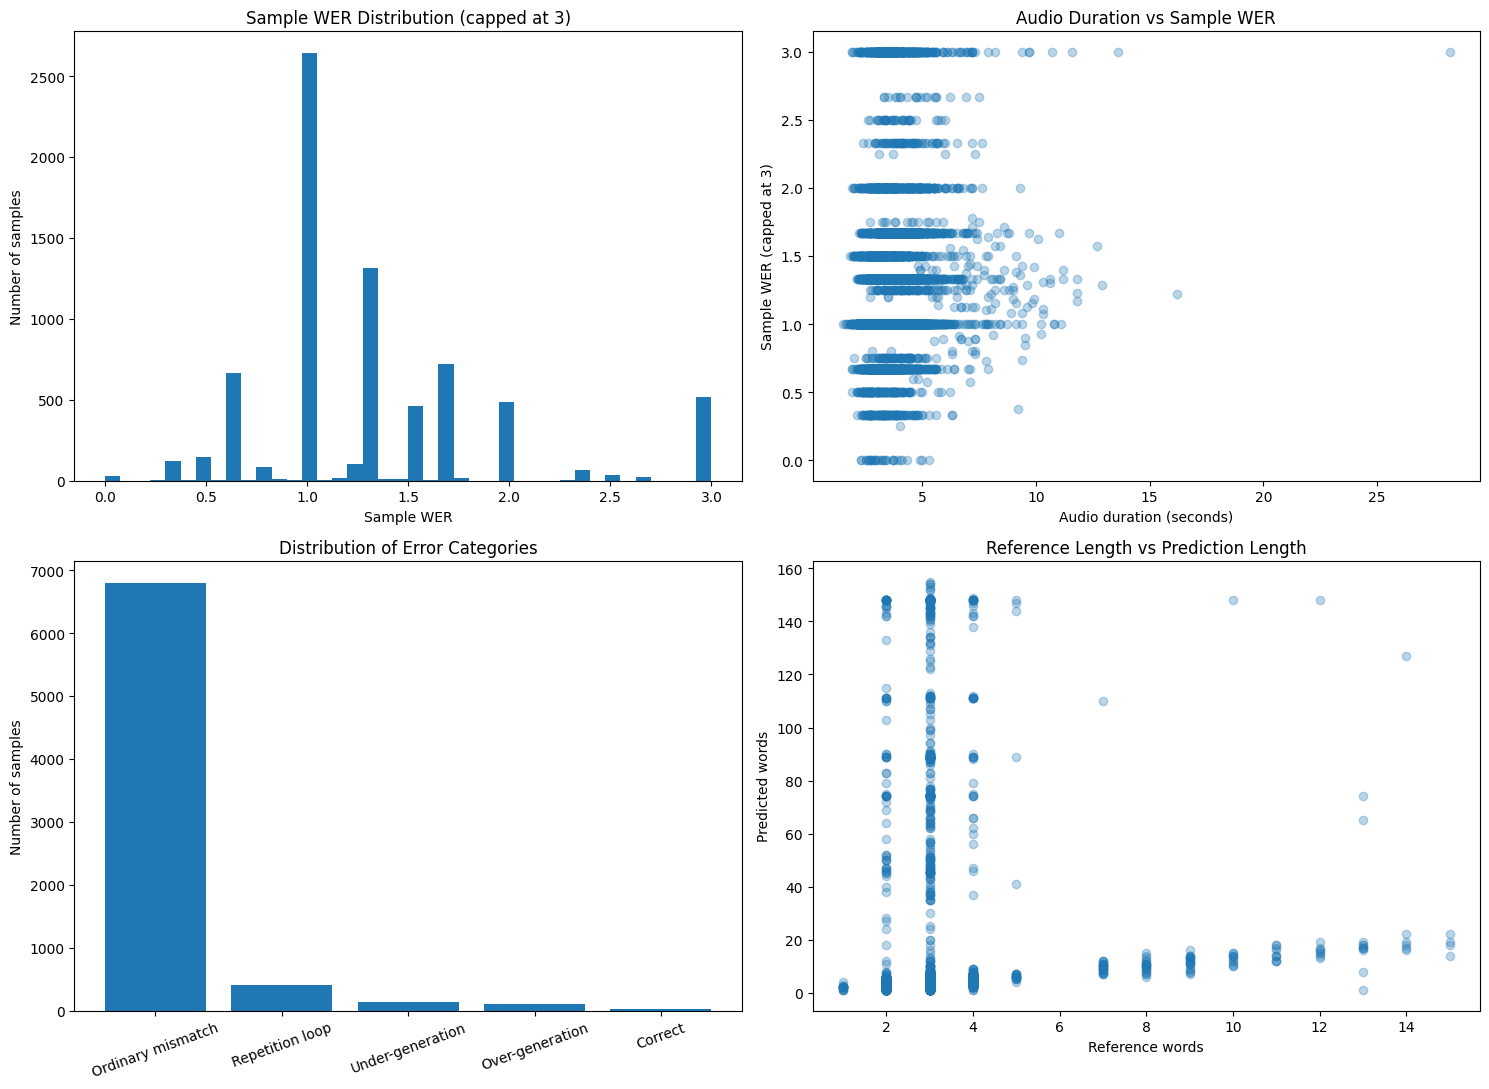

ERROR CATEGORY COUNTS


,samples
error_type,
Ordinary mismatch,6802
Repetition loop,410
Under-generation,142
Over-generation,111
Correct,30



ERROR CATEGORY PERCENTAGES


,percentage
error_type,
Ordinary mismatch,90.75
Repetition loop,5.47
Under-generation,1.89
Over-generation,1.48
Correct,0.40


In [47]:
import matplotlib.pyplot as plt
import pandas as pd
from jiwer import wer
from collections import Counter

# Prepare diagnostic dataframe
df_viz = predictions_df.copy()

df_viz["ref_clean"] = df_viz["reference"].apply(normalize_text)
df_viz["pred_clean"] = df_viz["prediction"].apply(normalize_text)

df_viz["ref_words"] = df_viz["ref_clean"].str.split().str.len()
df_viz["pred_words"] = df_viz["pred_clean"].str.split().str.len()

df_viz["sample_wer"] = df_viz.apply(
    lambda r: wer([r["ref_clean"]], [r["pred_clean"]]),
    axis=1
)

df_viz["length_ratio"] = (
    df_viz["pred_words"] / df_viz["ref_words"].clip(lower=1)
)

# Detect repetitive outputs using dominant word frequency
def repetition_ratio(text):
    words = text.split()

    if not words:
        return 0

    return Counter(words).most_common(1)[0][1] / len(words)

df_viz["repetition_ratio"] = df_viz["pred_clean"].apply(
    repetition_ratio
)

# Assign approximate error categories
def classify_error(row):

    if row["ref_clean"] == row["pred_clean"]:
        return "Correct"

    if row["pred_words"] >= 8 and row["repetition_ratio"] >= 0.40:
        return "Repetition loop"

    if row["length_ratio"] >= 3:
        return "Over-generation"

    if row["length_ratio"] <= 0.5:
        return "Under-generation"

    return "Ordinary mismatch"


df_viz["error_type"] = df_viz.apply(classify_error, axis=1)

# Create four visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# A. WER distribution, capped at 3 for readability
axes[0, 0].hist(
    df_viz["sample_wer"].clip(upper=3),
    bins=40
)
axes[0, 0].set_title("Sample WER Distribution (capped at 3)")
axes[0, 0].set_xlabel("Sample WER")
axes[0, 0].set_ylabel("Number of samples")

# B. Duration vs WER
axes[0, 1].scatter(
    df_viz["duration_seconds"],
    df_viz["sample_wer"].clip(upper=3),
    alpha=0.3
)
axes[0, 1].set_title("Audio Duration vs Sample WER")
axes[0, 1].set_xlabel("Audio duration (seconds)")
axes[0, 1].set_ylabel("Sample WER (capped at 3)")

# C. Error category distribution
category_counts = df_viz["error_type"].value_counts()

axes[1, 0].bar(
    category_counts.index,
    category_counts.values
)
axes[1, 0].set_title("Distribution of Error Categories")
axes[1, 0].set_ylabel("Number of samples")
axes[1, 0].tick_params(axis="x", rotation=20)

# D. Reference vs prediction length
axes[1, 1].scatter(
    df_viz["ref_words"],
    df_viz["pred_words"],
    alpha=0.3
)
axes[1, 1].set_title("Reference Length vs Prediction Length")
axes[1, 1].set_xlabel("Reference words")
axes[1, 1].set_ylabel("Predicted words")

plt.tight_layout()
plt.show()

# Numerical summary
print("ERROR CATEGORY COUNTS")
display(category_counts.to_frame("samples"))

print("\nERROR CATEGORY PERCENTAGES")
display(
    (category_counts / len(df_viz) * 100)
    .round(2)
    .to_frame("percentage")
)

### 13.1 Inspect the WER distribution and representative mismatches

Use percentiles to understand the skew of sample-level WER. Review both the worst examples and a reproducible random sample of ordinary mismatches.

In [48]:
# 1. Summary of sample-level WER
print("Sample WER statistics:")
display(df_viz["sample_wer"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("WER"))

# 2. Inspect 15 ordinary mismatches with the highest WER
ordinary = df_viz[
    df_viz["error_type"] == "Ordinary mismatch"
].sort_values("sample_wer", ascending=False)

print("Worst ordinary mismatches:")
display(
    ordinary[
        [
            "file_id",
            "duration_seconds",
            "ref_clean",
            "pred_clean",
            "ref_words",
            "pred_words",
            "sample_wer"
        ]
    ].head(15)
)

# 3. Inspect 15 randomly selected ordinary mismatches
print("Random ordinary mismatches:")
display(
    ordinary.sample(
        n=min(15, len(ordinary)),
        random_state=42
    )[
        [
            "file_id",
            "duration_seconds",
            "ref_clean",
            "pred_clean",
            "sample_wer"
        ]
    ]
)

Sample WER statistics:


,WER
count,7495.000000
mean,3.302872
std,8.934060
min,0.000000
25%,1.000000
50%,1.250000
75%,1.571429
90%,2.000000
95%,21.333333
99%,49.333333


Worst ordinary mismatches:


,file_id,duration_seconds,ref_clean,pred_clean,ref_words,pred_words,sample_wer
4642,a15e1d0a23,5.6,अन्तरिक्ष औपनिवेशीकरणको औचित्यमा,अन तरिक्चा अपनी वेशि करन को अव चित्यमा,3,8,2.666667
4799,a62622918d,7.5,पाइलाहरूका बारेमा बताइएको,पाईला और का बारे मां पता ही एको,3,8,2.666667
4716,a42bfa586c,4.7,अद्यापि अस्तित्वमा रहेको,अद्धापी अष्टित्वामा रहे को अग्टापी अष्टित्वामा...,3,8,2.666667
6556,e1aa329614,4.0,कतिपय साथीहरूलाई उनीहरूको,कति पए साथि हरु लाय उनी हरु को,3,8,2.666667
1769,3bb2c9d021,3.8,अध्ययन अनुसन्धान गर्ने,अद्यें अनु संदान करने अद्यें अनु संदान करने,3,8,2.666667
793,1a1457bda3,5.6,२०६६ सालको पद्मश्री,ती हाँट सैसे ती साल को पद माश्री,3,8,2.666667
4274,929f883aca,6.9,हजुरको पुनरागमनमा अन्तर्हृदयबाट,अजुर को पुनर अगमन मा अंतर रिदे बाट़,3,8,2.666667
961,20291d5be7,3.3,लिनुपर्दछ किनकि यस,लिन उ पर द़ चकी न की येस,3,8,2.666667
2788,5f476a0038,5.5,अहमदनगर महाराष्ट्रको सबैभन्दा,अहमाद नागर महर आश्टर को सबे बन द,3,8,2.666667
1680,3807dd2590,4.7,तापमानमा निर्भर गर्दछ,ताप मान मान निर भर कर ता सा,3,8,2.666667


Random ordinary mismatches:


,file_id,duration_seconds,ref_clean,pred_clean,sample_wer
5686,c35a0de137,4.7,अन्तत सङ्ख्याको अवधारणाको,अन्तत संख्या को अबदारना को,1.333333
2178,49b55e9395,4.5,भएको पुष्टि हुन्छ,बायको प्रश्टी वेंचार,1.000000
6926,ed1a83d8ce,3.9,रूपमै सुरक्षित राखे,रुप मैं सुरच्छित राहे,1.333333
5905,cab5055384,3.0,यी भाषाहरू एकाआपसमा,इबासा और एक अपस्मा,1.333333
316,0a10c88aae,3.5,आफ्नो बगैँचाबाट कलमी,अप्मो बगेजा बार्टा कलमि,1.333333
5653,c26cc89e70,5.7,उपाय प्रतिदिन महामृत्युञ्जय,उपाया प्रतिदिन महाम रिट्यूं जए,1.333333
2972,653a4a837b,3.0,पाँच सन्तानमध्ये,पाध संटान मुद्ध,1.500000
1027,229cba5e6f,3.6,रुद्री आदिको ज्ञान,रुद्री आदिको ज्यान,0.333333
4566,9e5f16c3cf,3.3,झुला गाविस गाएको,जुला गाई भी सर गाये को,2.000000
6463,de1e144aad,4.2,केही अव्यय शब्दमा,किर्ही अवेयो सब दमा,1.333333


### 13.2 Quantify high-error samples

Count utterances above selected sample-WER thresholds and summarize their audio duration and text lengths. These thresholds are for error analysis, not alternative benchmark definitions.

In [49]:
# Count samples at different WER thresholds
thresholds = [1, 2, 3, 5, 10, 20]

for threshold in thresholds:
    count = (df_viz["sample_wer"] >= threshold).sum()

    print(
        f"WER >= {threshold:2}: "
        f"{count:5} samples "
        f"({count / len(df_viz) * 100:.2f}%)"
    )

# Compare extreme samples with ordinary samples
extreme = df_viz[df_viz["sample_wer"] >= 5]

print("\nExtreme error samples:", len(extreme))
print("Average reference words:", extreme["ref_words"].mean())
print("Average predicted words:", extreme["pred_words"].mean())
print("Average audio duration:", extreme["duration_seconds"].mean())
print("Average WER:", extreme["sample_wer"].mean())

WER >=  1:  6435 samples (85.86%)
WER >=  2:  1132 samples (15.10%)
WER >=  3:   519 samples (6.92%)
WER >=  5:   478 samples (6.38%)
WER >= 10:   462 samples (6.16%)
WER >= 20:   381 samples (5.08%)

Extreme error samples: 478
Average reference words: 3.0606694560669454
Average predicted words: 98.51255230125523
Average audio duration: 3.9564853556485358
Average WER: 33.902534216132544


### 13.3 Plot the long-tailed sample-WER distribution

A logarithmic y-axis makes the low-frequency extreme-error tail easier to inspect. Sample-level WER can exceed 1.0 (100%) when insertions are numerous.

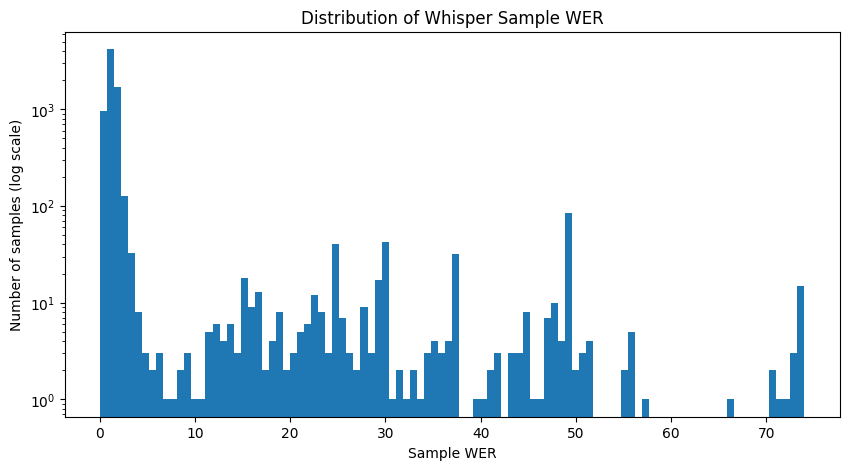

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_viz["sample_wer"],
    bins=100
)

plt.yscale("log")
plt.xlabel("Sample WER")
plt.ylabel("Number of samples (log scale)")
plt.title("Distribution of Whisper Sample WER")

plt.show()

### 13.4 Inspect the most extreme examples

Review the highest-WER predictions to determine whether failures are dominated by repetitions, unrelated text, or other recognition errors.

In [51]:
display(
    extreme.sort_values(
        "sample_wer",
        ascending=False
    )[
        [
            "file_id",
            "duration_seconds",
            "ref_clean",
            "pred_clean",
            "ref_words",
            "pred_words",
            "sample_wer"
        ]
    ].head(15)
)

,file_id,duration_seconds,ref_clean,pred_clean,ref_words,pred_words,sample_wer
1618,36c23f4933,1.9,सारिएका छन्,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
1336,2de965d9de,4.1,२०१८ असारमा,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
4510,9b965d84ea,2.3,सकेन भन्ने,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3532,780fff944e,4.2,आइसिसी एसोसिएट,अईश्वाद अप आप आप आप आप आप आप आप आप आप आप आप आप...,2,148,74.0
5992,cd596e7a94,2.7,कुनै ऐतिहासिक,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
2288,4df473fb0f,2.3,धोका पाइनेछ,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
4100,8d7e4fe6f1,3.5,सुनिश्चित गर्ने,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
2044,4422450561,4.9,डोनाल्ड थम्पसनलाई,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3426,745d70ae1f,3.3,स्वरूपले विवेचना,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0
3635,7cd336e97d,3.5,सजिलोको लागी,तो तो तो तो तो तो तो तो तो तो तो तो तो तो तो त...,2,148,74.0


## 14. Estimate the contribution of extreme errors

Use sample-level WER multiplied by the number of reference words to recover the per-utterance edit count, then estimate the share contributed by samples with WER ≥ 5.

The WER calculated after excluding extreme samples is **diagnostic only**. It must not replace the full-test benchmark because removing difficult samples would bias the reported result.

In [52]:
# Identify extreme samples
df_viz["is_extreme"] = df_viz["sample_wer"] >= 5
df_viz["is_repetition"] = df_viz["error_type"] == "Repetition loop"

# Estimate edit errors per sample:
# sample WER = edit errors / reference words
df_viz["estimated_errors"] = (
    df_viz["sample_wer"] * df_viz["ref_words"]
)

# Overlap
print("Extreme samples:", df_viz["is_extreme"].sum())
print(
    "Extreme samples also classified as repetition loops:",
    (df_viz["is_extreme"] & df_viz["is_repetition"]).sum()
)

print(
    "Repetition loops outside extreme group:",
    (df_viz["is_repetition"] & ~df_viz["is_extreme"]).sum()
)

# Error contribution
total_errors = df_viz["estimated_errors"].sum()
extreme_errors = df_viz.loc[
    df_viz["is_extreme"], "estimated_errors"
].sum()

print("\nEstimated total edit errors:", round(total_errors))
print("Errors from extreme samples:", round(extreme_errors))
print(
    "Share of errors from extreme samples:",
    round(extreme_errors / total_errors * 100, 2),
    "%"
)

# Diagnostic WER excluding extreme samples
remaining = df_viz[~df_viz["is_extreme"]]

diagnostic_wer = (
    remaining["estimated_errors"].sum()
    / remaining["ref_words"].sum()
)

print(
    "\nDiagnostic corpus WER without extreme samples:",
    round(diagnostic_wer, 4)
)

Extreme samples: 478
Extreme samples also classified as repetition loops: 407
Repetition loops outside extreme group: 3

Estimated total edit errors: 72157
Errors from extreme samples: 47035
Share of errors from extreme samples: 65.18 %

Diagnostic corpus WER without extreme samples: 1.2042


### 14.1 Compare heuristic error groups

Cross-tabulate extreme errors and the initial repetition-loop detector. Compare group-level duration, reference length, prediction length, and WER. This helps reveal where the first detector misses phrase-level repetition.

In [53]:
# Cross-tabulation of error groups
print("Extreme vs repetition overlap:")

display(pd.crosstab(
    df_viz["is_extreme"],
    df_viz["is_repetition"],
    rownames=["WER >= 5"],
    colnames=["Repetition loop"]
))

# Compare group characteristics
df_viz["group"] = "Other samples"

df_viz.loc[
    df_viz["is_extreme"] & df_viz["is_repetition"],
    "group"
] = "Extreme repetition"

df_viz.loc[
    df_viz["is_extreme"] & ~df_viz["is_repetition"],
    "group"
] = "Extreme non-repetition"

df_viz.loc[
    ~df_viz["is_extreme"] & df_viz["is_repetition"],
    "group"
] = "Non-extreme repetition"

summary = df_viz.groupby("group").agg(
    samples=("file_id", "count"),
    avg_duration=("duration_seconds", "mean"),
    avg_reference_words=("ref_words", "mean"),
    avg_prediction_words=("pred_words", "mean"),
    avg_WER=("sample_wer", "mean")
).round(2)

display(summary)

# Inspect extreme non-repetition samples
other_extreme = df_viz[
    df_viz["is_extreme"] & ~df_viz["is_repetition"]
].sort_values("sample_wer", ascending=False)

print("Extreme non-repetition samples:", len(other_extreme))

display(
    other_extreme[
        [
            "file_id",
            "duration_seconds",
            "ref_clean",
            "pred_clean",
            "ref_words",
            "pred_words",
            "sample_wer"
        ]
    ].head(20)
)

Extreme vs repetition overlap:


Repetition loop,False,True
WER >= 5,,
False,7014,3
True,71,407


,samples,avg_duration,avg_reference_words,avg_prediction_words,avg_WER
group,,,,,
Extreme non-repetition,71,3.80,2.82,92.39,33.70
Extreme repetition,407,3.98,3.10,99.58,33.94
Non-extreme repetition,3,4.33,3.33,9.67,2.97
Other samples,7014,3.76,2.97,3.82,1.22


Extreme non-repetition samples: 71


,file_id,duration_seconds,ref_clean,pred_clean,ref_words,pred_words,sample_wer
855,1d072a6163,4.4,सिद्धान्त बन्यो,तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ...,2,148,74.000000
3532,780fff944e,4.2,आइसिसी एसोसिएट,अईश्वाद अप आप आप आप आप आप आप आप आप आप आप आप आप...,2,148,74.000000
722,18ed803248,2.7,एमए गरे,में आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,2,146,73.000000
7259,f8f10bc846,4.2,सहर्ष धन्यवाद,ज़ाए तो आप आप आप आप आप आप आप आप आप आप आप आप आप...,2,143,71.500000
5026,ae6c333adb,2.8,नयाँ सरकारमा,नहीं आश्वाँ आप आप आप आप आप आप आप आप आप आप आप आ...,2,142,71.000000
1743,3a7eaa8ef6,3.3,यहाँ देशको,यहा देस को यहा देस को यहा देस को यहा देस को यह...,2,133,66.500000
6479,de34439039,3.4,प्रत्येक गुठीका,पर तेक गुटीका आप पर तेक गुटीका आप पर तेक गुटीक...,2,115,57.500000
2301,4dc36006ba,4.3,सहन नसकी,तब आद नाशा की अगर नाशा की अगर नाशा की अगर नाशा...,2,103,51.500000
245,08bda1a56b,2.6,साँच्चै नै एक्लिए,अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अ...,3,154,51.333333
5076,aff42224a0,4.5,सञ्चारमाध्यमले सबैभन्दा धेरै,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ...,3,154,51.333333


### 14.2 Improve repetition detection with repeated n-grams

The revised heuristic checks repeated 2-, 3-, and 4-word sequences. It is more sensitive to repeated phrases than a detector based only on one frequently repeated word.

> **Interpretation caution:** a high repeated n-gram score identifies repetitive text patterns; it does not by itself prove a decoder loop. Validate representative cases against the audio.

In [54]:
from collections import Counter

def repeated_ngram_ratio(text, n):
    words = text.split()

    if len(words) < n:
        return 0

    ngrams = [
        tuple(words[i:i+n])
        for i in range(len(words)-n+1)
    ]

    counts = Counter(ngrams)

    repeated = sum(
        count for count in counts.values()
        if count > 1
    )

    return repeated / len(ngrams)


# Calculate repeated phrase ratios
for n in [2, 3, 4]:
    df_viz[f"repeat_{n}gram"] = df_viz["pred_clean"].apply(
        lambda x: repeated_ngram_ratio(x, n)
    )

# Improved heuristic
df_viz["repetition_score"] = df_viz[
    ["repeat_2gram", "repeat_3gram", "repeat_4gram"]
].max(axis=1)

df_viz["repetition_detected"] = (
    (df_viz["repetition_score"] >= 0.25)
    & (df_viz["pred_words"] >= 8)
)

print("New repetition-like samples:",
      df_viz["repetition_detected"].sum())

print("\nExtreme samples with detected repetition:",
      (
          df_viz["is_extreme"]
          & df_viz["repetition_detected"]
      ).sum())

# Inspect previously missed extreme samples
missed = df_viz[
    df_viz["is_extreme"]
    & ~df_viz["is_repetition"]
].sort_values("sample_wer", ascending=False)

display(
    missed[
        [
            "ref_clean",
            "pred_clean",
            "repeat_2gram",
            "repeat_3gram",
            "repeat_4gram",
            "repetition_score"
        ]
    ].head(15)
)

New repetition-like samples: 503

Extreme samples with detected repetition: 478


,ref_clean,pred_clean,repeat_2gram,repeat_3gram,repeat_4gram,repetition_score
855,सिद्धान्त बन्यो,तब आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ...,0.986395,0.952055,0.924138,0.986395
3532,आइसिसी एसोसिएट,अईश्वाद अप आप आप आप आप आप आप आप आप आप आप आप आप...,0.979592,0.958904,0.937931,0.979592
722,एमए गरे,में आप आप आप आप आप आप आप आप आप आप आप आप आप आप ...,0.979310,0.958333,0.930070,0.979310
7259,सहर्ष धन्यवाद,ज़ाए तो आप आप आप आप आप आप आप आप आप आप आप आप आप...,0.971831,0.950355,0.928571,0.971831
5026,नयाँ सरकारमा,नहीं आश्वाँ आप आप आप आप आप आप आप आप आप आप आप आ...,0.971631,0.935714,0.906475,0.971631
1743,यहाँ देशको,यहा देस को यहा देस को यहा देस को यहा देस को यह...,1.000000,1.000000,1.000000,1.000000
6479,प्रत्येक गुठीका,पर तेक गुटीका आप पर तेक गुटीका आप पर तेक गुटीक...,1.000000,1.000000,0.982143,1.000000
2301,सहन नसकी,तब आद नाशा की अगर नाशा की अगर नाशा की अगर नाशा...,0.970588,0.970297,0.970000,0.970588
245,साँच्चै नै एक्लिए,अप यह तो अप यह तो अप यह तो अप यह तो अप यह तो अ...,1.000000,0.993421,0.980132,1.000000
5076,सञ्चारमाध्यमले सबैभन्दा धेरै,अप आप आप आप आप आप आप आप आप आप आप आप आप आप आप आ...,0.980392,0.960526,0.927152,0.980392


## 15. Audio-level inspection: waveform and log-mel spectrogram

Compare representative repetition failures with a relatively successful sample. The waveform helps inspect amplitude and silence; the log-mel spectrogram shows how acoustic energy changes over time and frequency.

Listen to each recording and compare it with its reference. These plots can reveal possible audio-quality or alignment issues, but they cannot independently establish why the decoder repeated text.

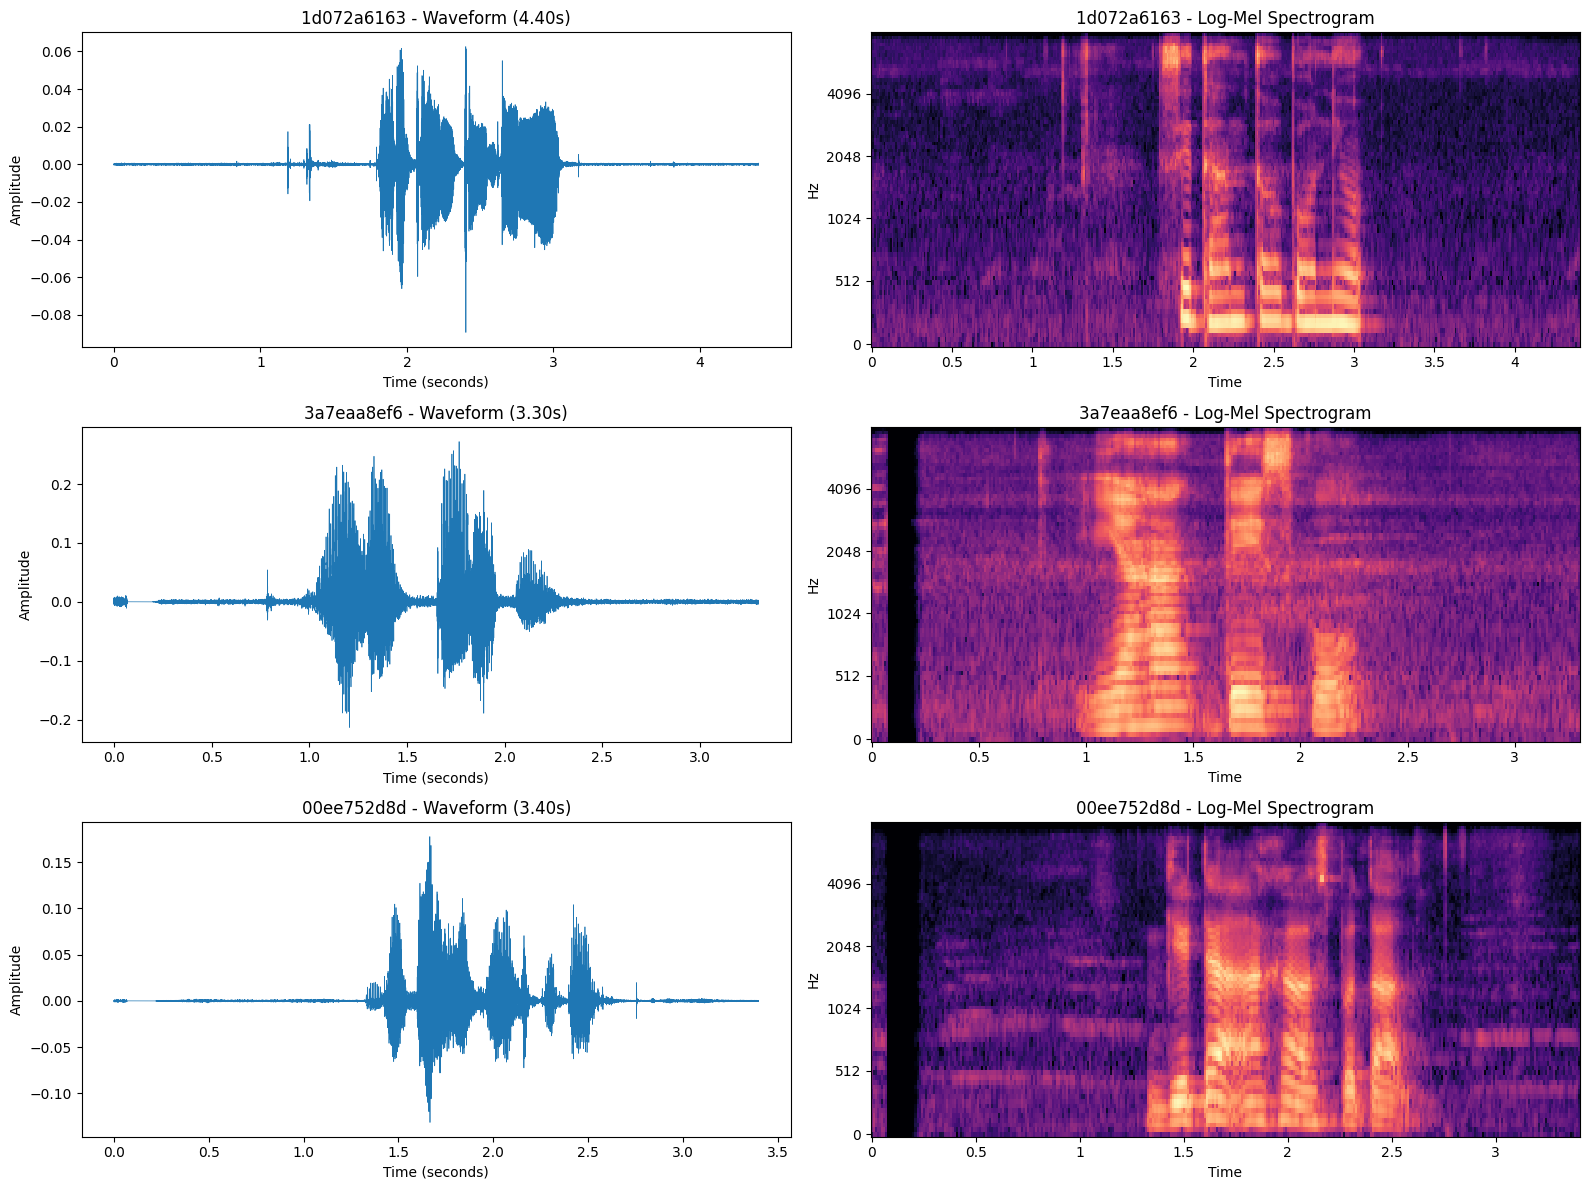

Audio: 1d072a6163


Audio: 3a7eaa8ef6


Audio: 00ee752d8d


In [55]:
import os
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import Audio, display

sample_ids = [
    "1d072a6163",
    "3a7eaa8ef6",
    "00ee752d8d"
]

fig, axes = plt.subplots(
    len(sample_ids), 2,
    figsize=(16, 12)
)

for i, file_id in enumerate(sample_ids):

    audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"

    # Load original audio
    audio, sr = sf.read(audio_path)

    # Convert stereo to mono if necessary
    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    duration = len(audio) / sr
    time_axis = np.arange(len(audio)) / sr

    # Waveform
    axes[i, 0].plot(time_axis, audio, linewidth=0.5)
    axes[i, 0].set_title(
        f"{file_id} - Waveform ({duration:.2f}s)"
    )
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")

    # Log-mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio.astype(np.float32),
        sr=sr,
        n_fft=400,
        hop_length=160,
        n_mels=80,
        fmax=8000
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    librosa.display.specshow(
        mel_db,
        sr=sr,
        hop_length=160,
        x_axis="time",
        y_axis="mel",
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f"{file_id} - Log-Mel Spectrogram"
    )

plt.tight_layout()
plt.show()

# Listen to each recording
for file_id in sample_ids:
    audio_path = f"{LOCAL_AUDIO_DIR}/{file_id}.flac"
    audio, sr = sf.read(audio_path)

    print(f"Audio: {file_id}")
    display(Audio(audio.T, rate=sr))

## 16. Baseline findings

### Recorded zero-shot results

| Metric | Result |
|---|---:|
| Test utterances | 7,495 |
| Corpus WER | 323.21% |
| Corpus CER | 186.95% |
| Total test audio | 7.86 hours |
| Recorded inference time | 90.23 minutes |
| Throughput | 1.38 samples/second |
| Real-time factor | 0.1912 |

### Main error-analysis observations

- Many predictions are substantially longer than their references.
- Repetitive token and phrase generation accounts for a large share of extreme sample-level errors.
- The first repetition detector missed phrase-level loops; the repeated n-gram heuristic identified all 478 samples with sample WER ≥ 5 in this run.
- Removing extreme samples lowers diagnostic corpus WER to 1.2042, but this is **not** a valid replacement for the full-test score.
- The Nepali language/task prompt was verified. Individual inference reproduced the repetition behavior, so batching alone does not explain it.
